# VQE en el simulador IonQ: ansatz hardware-efficient

El mismo Max-Cut de 5 nodos de los cuadernos 02 y 04, pero el circuito optimo se muestrea en el `ionq_simulator`. La optimizacion variacional se hace en local (sin coste) y solo el muestreo final viaja a IonQ.

IonQ usa iones atrapados con conectividad total. Un ansatz hardware-efficient como `EfficientSU2` encaja bien: capas locales de $R_Y$/$R_Z$ mas entrelazadores lineales, sin el coste por arista de QAOA.

Referencias: handbook ([VQE](https://iraitzm.github.io/qc-handbook/es/parts/algorithms/vqe.html)), cuaderno `04-vqe-maxcut.ipynb` de esta carpeta y `02-iqm-ionq-submission.ipynb` de la sesion 01.


In [1]:
%pip install -q qiskit qiskit-algorithms qiskit-aer qiskit-ibm-runtime qiskit-ionq dimod networkx matplotlib pylatexenc



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. El QUBO de partida (identico al de `04-vqe-maxcut.ipynb`)

Mismo grafo de 5 nodos y 6 aristas, misma matriz Q con signo de minimizacion. `ExactSolver` da la energia de referencia.


In [2]:
import networkx as nx
import numpy as np
import dimod

G = nx.Graph()
G.add_edges_from([(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 5)])
nodes = list(G.nodes)
n = len(nodes)
Q = np.zeros((n, n))
for u, v in G.edges:
    i, j = nodes.index(u), nodes.index(v)
    Q[i, i] += 1; Q[j, j] += 1; Q[i, j] -= 1; Q[j, i] -= 1
Q = -1.0 * Q  # minimizacion

bqm = dimod.BQM(Q, "BINARY")
optimo = float(dimod.ExactSolver().sample(bqm).first.energy)
print('Referencia exacta: E =', optimo)
print(dimod.ExactSolver().sample(bqm).truncate(4))


Referencia exacta: E = -5.0
   0  1  2  3  4 energy num_oc.
0  0  1  1  0  0   -5.0       1
1  1  0  0  1  0   -5.0       1
2  0  1  1  0  1   -5.0       1
3  1  0  0  1  1   -5.0       1
['BINARY', 4 rows, 4 samples, 5 variables]


In [3]:
lineal, cuadratico, offset = bqm.to_ising()

print('h =', dict(lineal))
print('J =', {(i, j): round(v, 3) for (i, j), v in cuadratico.items()})
print('offset =', round(offset, 3))

from qiskit.quantum_info import SparsePauliOp

# OJO convencion Qiskit (little-endian): el qubit 0 es el caracter de la
# derecha, igual que en los cuadernos 02 y 04.
terminos = []
for i, h in lineal.items():
    s = ['I'] * n
    s[n - 1 - i] = 'Z'
    terminos.append((''.join(s), float(h)))
for (i, j), J in cuadratico.items():
    s = ['I'] * n
    s[n - 1 - i] = 'Z'
    s[n - 1 - j] = 'Z'
    terminos.append((''.join(s), float(J)))
H_op = SparsePauliOp.from_list(terminos)
print('Terminos de Pauli:', len(terminos))


h = {0: np.float64(0.0), 1: np.float64(0.0), 2: np.float64(0.0), 3: np.float64(0.0), 4: np.float64(0.0)}
J = {(1, 0): np.float64(0.5), (2, 0): np.float64(0.5), (3, 1): np.float64(0.5), (3, 2): np.float64(0.5), (4, 2): np.float64(0.5), (4, 3): np.float64(0.5)}
offset = -3.0
Terminos de Pauli: 11


## 2. Ansatz hardware-efficient (`EfficientSU2`)

QAOA hereda su estructura del problema (coste + mixer, $2p$ parametros). VQE usa un circuito genérico pensado para el hardware: rotaciones $R_Y$/$R_Z$ por qubit y entrelazadores `CX` lineales.

* Parametros: $2n(\mathrm{reps}+1)$ (30 con $n=5$, reps=2).
* Profundidad: crece con reps, no con las aristas (QAOA paga un $R_{ZZ}$ por arista y capa).
* En IonQ la conectividad es total, asi que el entrelazado lineal no paga SWAPs extra. En la seccion 4 transpilamos el circuito optimo a puertas nativas (`GPI`, `GPI2`, `MS`) antes de enviarlo: es lo preferido porque evita una segunda transpilacion en la nube y muestra el coste real en puertas de dos qubits.


qubits: 5 | parametros: 30
puertas: {'r': 15, 'p': 15, 'cx': 8}
profundidad (descompuesto): 12


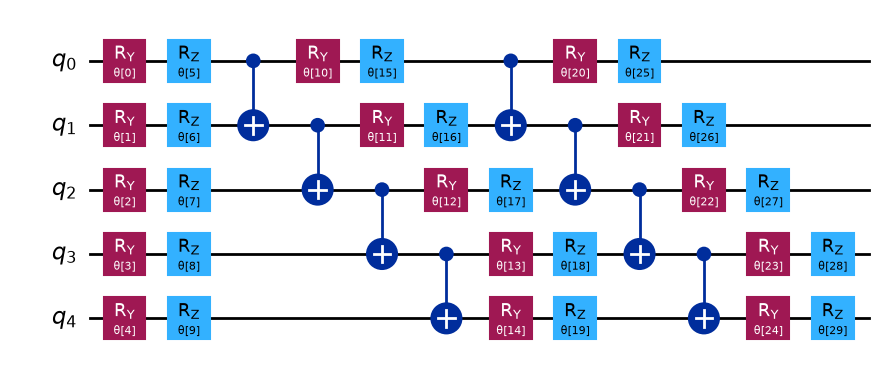

In [4]:
from qiskit.circuit.library import efficient_su2

ansatz = efficient_su2(n, reps=2, entanglement='linear')
print('qubits:', ansatz.num_qubits, '| parametros:', ansatz.num_parameters)
print('puertas:', dict(ansatz.decompose().count_ops()))
print('profundidad (descompuesto):', ansatz.decompose().depth())
ansatz.draw('mpl')


## 3. VQE local con COBYLA (sin coste)

El bucle variacional completo en la QPU seria un job por evaluacion (lento y con coste). En clase se optimiza en local con `StatevectorEstimator` y se reserva IonQ para muestrear el circuito optimo ya fijado. Punto inicial aleatorio pequeno con semilla fija, igual que en el cuaderno 04.


VQE <H_QUBO> = -4.38 | optimo exacto = -5.0


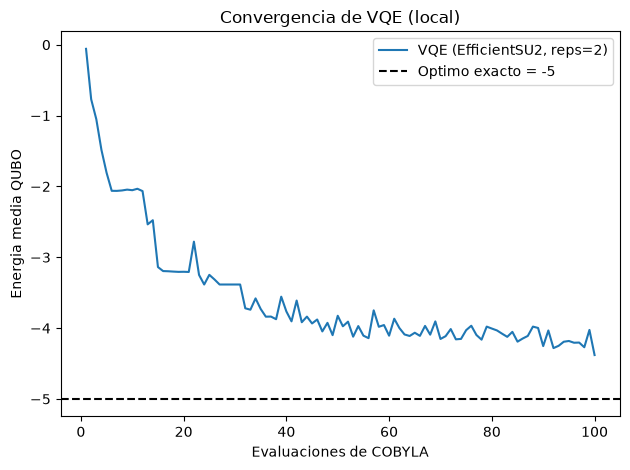

In [5]:
import matplotlib.pyplot as plt
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA
from qiskit.primitives import StatevectorEstimator

rng = np.random.default_rng(42)
punto_inicial = 0.1 * rng.standard_normal(ansatz.num_parameters)

evaluaciones, energias = [], []
def registrar(evaluacion, parametros, media, metadatos):
    evaluaciones.append(evaluacion)
    energias.append(float(media) + offset)

vqe = VQE(StatevectorEstimator(), ansatz, COBYLA(maxiter=100),
          initial_point=punto_inicial, callback=registrar)
r = vqe.compute_minimum_eigenvalue(H_op)
print('VQE <H_QUBO> =', round(float(r.optimal_value) + offset, 3), '| optimo exacto =', optimo)

plt.plot(evaluaciones, energias, label='VQE (EfficientSU2, reps=2)')
plt.axhline(optimo, color='black', linestyle='--', label=f'Optimo exacto = {optimo:g}')
plt.xlabel('Evaluaciones de COBYLA'); plt.ylabel('Energia media QUBO')
plt.title('Convergencia de VQE (local)'); plt.legend(); plt.tight_layout(); plt.show()


## 4. Del estimador local al simulador IonQ

El ansatz de VQE no trae medicion. Para muestrear hay que fijar los parametros (`assign_parameters`), abrir la caja `EfficientSU2` (`decompose`, Aer e IonQ no la entienden como caja) y anadir bits clasicos (`measure_all`). Tanto Aer como IonQ devuelven conteos little-endian: el qubit 0 es el caracter de la derecha, asi que la energia usa `bitstr[::-1]`.

El simulador de IonQ es gratuito pero pide API key. Consigue la tuya en [cloud.ionq.com](https://cloud.ionq.com) y exportala antes de arrancar Jupyter:

```bash
export IONQ_API_KEY="tu_api_key_aqui"
```

Backends tipicos: `ionq_simulator` (simulador, sin coste), `ionq_qpu.aria-1` (25 qubits) y `ionq_qpu.forte-1` (36 qubits). Aqui solo usamos el simulador.

IonQ expone dos lenguajes (`gateset`): `qis` (puertas Qiskit como `rx`, `cx`) y `native` (`GPI`, `GPI2` de un qubit mas `MS` de dos qubits en el simulador y Aria; Forte usa `ZZ`). El nativo es lo preferido: lo transpilamos en local con el `Target` del backend, contamos las `MS` reales (una por cada `CX`, sin SWAPs gracias a la conectividad total) y la nube ya no tiene que recompilar nada.


profundidad: 13 | puertas 2q: 8
Aer: mejor=01001 E=-5.0 shots=1145


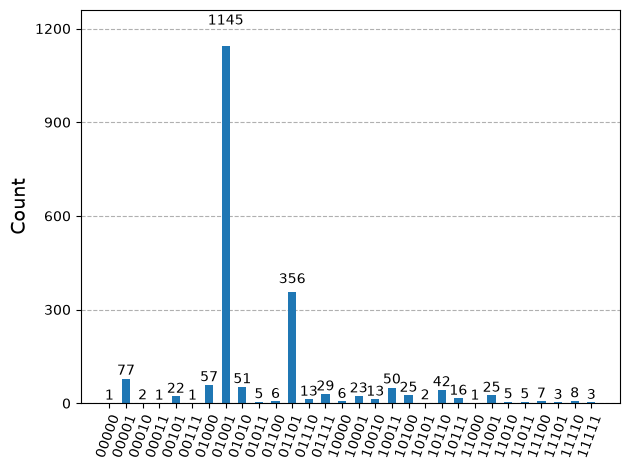

In [6]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def energia(bitstr, Q):
    x = np.array([int(b) for b in bitstr[::-1]])  # qubit 0 primero
    return float(x @ Q @ x)

# Circuito optimo listo para muestrear: parametros fijados + medicion.
qc_opt = ansatz.assign_parameters(r.optimal_point).decompose()  # abrir EfficientSU2
qc_opt.measure_all()
print('profundidad:', qc_opt.depth(), '| puertas 2q:', qc_opt.count_ops().get('cx', 0))

# Referencia local: siempre funciona, sin API key.
sim = AerSimulator()
counts_aer = sim.run(qc_opt, shots=2000).result().get_counts(qc_opt)
mejor_aer = min(counts_aer, key=lambda s: energia(s, Q))
print(f'Aer: mejor={mejor_aer} E={energia(mejor_aer, Q):.1f} shots={counts_aer[mejor_aer]}')

plot_histogram(counts_aer)


In [10]:
from qiskit import transpile
from qiskit.circuit import Parameter
from qiskit.circuit.measure import Measure
from qiskit.circuit.reset import Reset
from qiskit.transpiler import Target
from qiskit_ionq import ionq_equivalence_library
from qiskit_ionq.ionq_gates import GPIGate, GPI2Gate, MSGate

ionq_equivalence_library.add_equivalences()  # U -> GPI/GPI2, CX -> MS

# Mismo target que expone el backend con gateset="native" en el
# simulador (familia MS; Forte usa ZZ en su lugar).
phi = Parameter('phi')
phi0, phi1, theta = Parameter('phi0'), Parameter('phi1'), Parameter('theta')
target_nativo = Target(num_qubits=n)
for puerta in (GPIGate(phi), GPI2Gate(phi), MSGate(phi0, phi1, theta)):
    target_nativo.add_instruction(puerta)
for cls in (Measure, Reset):
    target_nativo.add_instruction(cls())

qc_nativo = transpile(qc_opt, target=target_nativo, optimization_level=3, seed_transpiler=7)
print('QIS   :', dict(qc_opt.count_ops()))
print('Nativo:', dict(qc_nativo.count_ops()))
print('2q reales (MS):', qc_nativo.count_ops().get('ms', 0))


QIS   : {'r': 15, 'p': 15, 'cx': 8, 'measure': 5, 'barrier': 1}
Nativo: {'gpi2': 92, 'gpi': 30, 'ms': 8, 'measure': 5, 'barrier': 1}
2q reales (MS): 8


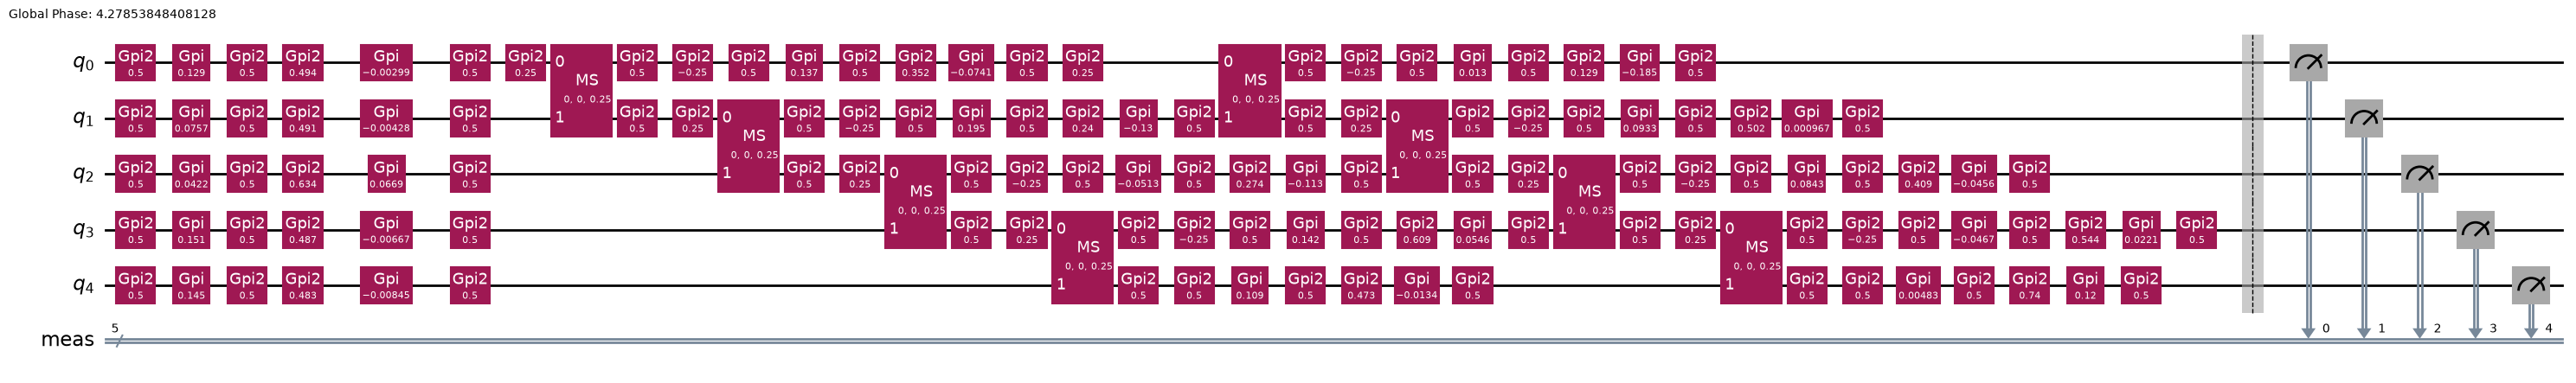

In [12]:
qc_nativo.draw('mpl', fold=-1)

In [13]:
import os
from getpass import getpass

SHOTS = 2000

api_key = os.environ.get('IONQ_API_KEY') or getpass('API Key de IonQ (vacio para omitir): ')
ionq_provider, ionq_sim, ionq_nativo = None, None, None
if api_key:
    try:
        from qiskit_ionq import IonQProvider
        ionq_provider = IonQProvider(token=api_key)
        ionq_sim = ionq_provider.get_backend('ionq_simulator')
        ionq_nativo = ionq_provider.get_backend('ionq_simulator', gateset='native')
        print('Backend IonQ:', ionq_nativo.name, '| gateset:', ionq_nativo.gateset())
    except Exception as e:
        print('No se pudo conectar a IonQ:', e)
else:
    print('Sin API key: se omite el envio a IonQ (queda la referencia Aer).')


/home/iraitz/Documentos/Falcondale/Clientes/GAIA/gaia-workshop-tech/.venv/lib/python3.12/site-packages/qiskit_ionq/ionq_backend.py:129: IonQTranspileLevelWarning: Transpiler default optimization_level=2. IonQ (QIS) recommends 0-1 to avoid aggressive re-synthesis; use transpile(..., optimization_level=1).
  warn_bad_transpile_level()


Backend IonQ: ionq_simulator | gateset: native


In [ ]:
counts_ionq = None
if ionq_nativo is not None:
    # qc_nativo ya viaja en puertas GPI/GPI2/MS: el backend nativo lo acepta tal cual.
    job_ionq = ionq_nativo.run(qc_nativo, shots=SHOTS)
    counts_ionq = job_ionq.result().get_counts()
    mejor_ionq = min(counts_ionq, key=lambda s: energia(s, Q))
    print(f'IonQ sim: mejor={mejor_ionq} E={energia(mejor_ionq, Q):.1f} shots={counts_ionq[mejor_ionq]}')
    print(f'Aer    : mejor={mejor_aer} E={energia(mejor_aer, Q):.1f} shots={counts_aer[mejor_aer]}')
else:
    print('Sin backend IonQ: queda la referencia Aer de la celda anterior.')

IonQ sim: mejor=01001 E=-5.0 shots=1065
Aer    : mejor=01001 E=-5.0 shots=1145


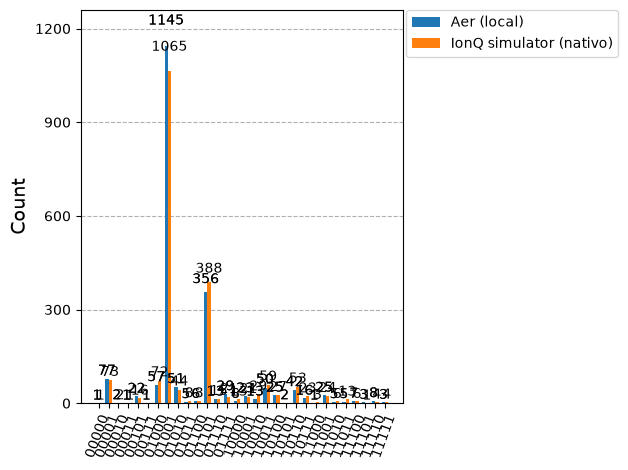

In [15]:
plot_histogram([counts_aer, counts_ionq], legend=['Aer (local)', 'IonQ simulator (nativo)'])

## 5. Coste y hardware real (solo lectura)

El simulador (`ionq_simulator`) no consume creditos de QPU. El hardware (`ionq_qpu.aria-1`, `ionq_qpu.forte-1`) si: cada evaluacion de COBYLA seria un job real, asi que el bucle completo solo tiene sentido con `reps=1` y pocas iteraciones, igual que el ejemplo IBM del cuaderno 02. Para VQE completo sobre IonQ se usa un estimador sobre el backend (`BackendEstimatorV2`) en lugar del `StatevectorEstimator` local. Ojo al cambiar de familia: el simulador y Aria entrelazan con `MS`, pero Forte usa `ZZ`; pedid el backend con `gateset='native'` y transpilad contra su `Target` para ver el coste real en cada caso.

La celda siguiente esta desactivada por defecto (`EJECUTAR_VQE_IONQ = False`). Activala solo con creditos y tras comprobar el coste en la consola de IonQ.


In [16]:
EJECUTAR_VQE_IONQ = True  # pon True solo con creditos y API key valida

if EJECUTAR_VQE_IONQ and ionq_sim is not None:
    from qiskit.primitives import BackendEstimatorV2
    from qiskit_algorithms import VQE as VQE_hw
    from qiskit_algorithms.optimizers import COBYLA as COBYLA_hw

    ansatz_hw = efficient_su2(n, reps=1, entanglement='linear')
    rng_hw = np.random.default_rng(7)
    x0_hw = 0.1 * rng_hw.standard_normal(ansatz_hw.num_parameters)
    vqe_hw = VQE_hw(BackendEstimatorV2(backend=ionq_sim),
                    ansatz_hw, COBYLA_hw(maxiter=25), initial_point=x0_hw)
    r_hw = vqe_hw.compute_minimum_eigenvalue(H_op)
    print('VQE en ionq_simulator <H_QUBO> =', round(float(r_hw.optimal_value) + offset, 3))
else:
    print('Bucle VQE en IonQ desactivado. Muestreo del optimo local: suficiente en clase.')


VQE en ionq_simulator <H_QUBO> = -3.052


## Para clase

* Contad parametros y puertas `cx` del ansatz: 30 parametros y 8 `cx` con reps=2. Donde paga QAOA el precio del grafo denso?
* Comparad `qc_opt.count_ops()` con `qc_nativo.count_ops()`: cada `cx` se vuelve una `MS` (8 en total, sin SWAPs). Por que no crece el numero de puertas de dos qubits?
* Comparad el mejor bitstring de Aer y del simulador IonQ: ambos deberian acercarse al optimo exacto (-5.0) o a su degenerado $Z_2$ (cada corte y su complementario empatan, esperad picos gemelos).
* Si COBYLA se estanca lejos del optimo, probad otra semilla o `reps=1`: menos parametros, superficie mas facil.
* Pregunta: con el mismo `maxiter`, quien llega mas cerca del optimo con el estimador local, VQE o QAOA $p=2$? Y que cambia al muestrear con 2000 shots en IonQ frente a Aer?
